<a href="https://colab.research.google.com/github/Vrindagop/skills-introduction-to-github/blob/main/05_support_vector_machines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Support Vector Machines**

_This notebook contains all the sample code and solutions to the exercises in chapter 5._

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/ageron/handson-ml3/blob/main/05_support_vector_machines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/ageron/handson-ml3/blob/main/05_support_vector_machines.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

Vrinda Gopakumar - Module 3 Assignment on SVM


# Setup

This project requires Python 3.7 or above:

In [77]:
import sys

assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [76]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

As we did in previous chapters, let's define the default font sizes to make the figures prettier:

In [75]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

And let's create the `images/svm` folder (if it doesn't already exist), and define the `save_fig()` function which is used through this notebook to save the figures in high-res for the book:

In [74]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "svm"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# Linear SVM Classification

Vrinda Gopakumar - Module 3 Assignment on SVM

# 10.

_Exercise: Train an SVM classifier on the Wine dataset, which you can load using `sklearn.datasets.load_wine()`. This dataset contains the chemical analysis of 178 wine samples produced by 3 different cultivators: the goal is to train a classification model capable of predicting the cultivator based on the wine's chemical analysis. Since SVM classifiers are binary classifiers, you will need to use one-versus-all to classify all 3 classes. What accuracy can you reach?_

First, let's fetch the dataset, look at its description, then split it into a training set and a test set:

In [54]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)

In [55]:
print(wine.DESCR)

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

## Wine Dataset and SVM Goal

Classes 0, 1, 2: the three cultivators (grape growers) in the same Italian region that produced the 178 wines: class 0 (59 wines), class 1(71), class 2(48). The numbers are just labels, not quality rankings.

SVM GOAL: given a wine's 13 chemical measurements(alcohol, flavanoids, proline, etc.), predict which cultivator made it. The SVM finds the boundary that seperates the classes with the widest margin, using the points closest to the boundary(support vectors).

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, random_state=42)

In [57]:
X_train.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
100,12.08,2.08,1.70,17.5,97.0,2.23,2.17,0.26,1.40,3.30,1.27,2.96,710.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
154,12.58,1.29,2.10,20.0,103.0,1.48,0.58,0.53,1.40,7.60,0.58,1.55,640.0
51,13.83,1.65,2.60,17.2,94.0,2.45,2.99,0.22,2.29,5.60,1.24,3.37,1265.0


In [58]:
y_train.head()

,target
2,0
100,1
122,1
154,2
51,0


Let's start simple, with a linear SVM classifier. It will automatically use the One-vs-All (also called One-vs-the-Rest, OvR) strategy, so there's nothing special we need to do to handle multiple classes. Easy, right?

In [59]:
from sklearn.svm import LinearSVC

lin_clf = LinearSVC(dual=True, random_state=42)
lin_clf.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC(dual=True, random_state=42)

Oh no! It failed to converge. Can you guess why? Do you think we must just increase the number of training iterations? Let's see:

LinearSVC failed to converge because the features in the Wine dataset have wildly different scales.

Why Scale Matters for SVMs:
Support Vector Machines find the widest possible decision boundary (the 'margin') between classes by calculating geometric distances between data points.

If you look at the dataset summary statistics:

Alcohol ranges from 11.0 to 14.8
Proline ranges from 278.0 to 1680.0
Because the values for Proline are hundreds of times larger than those for Alcohol, the Proline feature completely dominates the distance calculations. This makes the loss landscape incredibly elongated and steep in one direction, causing the optimization algorithm (coordinate descent in Liblinear) to bounce back and forth and fail to find the global minimum—even if you increase the number of iterations to 1,000,000.

Once feature scaling (StandardScaler) is applied, all features are transformed to have a mean of 0 and a standard deviation of 1. The optimization landscape becomes symmetric, allowing the algorithm to converge almost instantly.

In [73]:
lin_clf = LinearSVC(max_iter=1_000_000, dual=True, random_state=42)
lin_clf.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC(dual=True, max_iter=1000000, random_state=42)

Even with one million iterations, it still did not converge. There must be another problem.

Let's still evaluate this model with `cross_val_score`, it will serve as a baseline:

In [72]:
from sklearn.model_selection import cross_val_score

cross_val_score(lin_clf, X_train, y_train).mean()

np.float64(0.9774928774928775)

Well 91% accuracy on this dataset is not great. So did you guess what the problem is?

That's right, we forgot to scale the features! Always remember to scale the features when using SVMs:

Scaling puts all features on a similar range so none dominates just because of its units. Proline (hundreds) would otherwise overpower hue(around 1).

Standaradization: (value-mean) /std, so every feature ends up with mean 0 and SD 1.

In [71]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lin_clf = make_pipeline(StandardScaler(),
                        LinearSVC(dual=True, random_state=42))
lin_clf.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearsvc', LinearSVC(dual=True, random_state=42))])

Now it converges without any problem. Let's measure its performance:

In [70]:
from sklearn.model_selection import cross_val_score

cross_val_score(lin_clf, X_train, y_train).mean()

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


np.float64(0.8575498575498575)

Nice! We get 97.7% accuracy, that's much better.

Let's see if a kernelized SVM will do better. We will use a default `SVC` for now:

A kernelized SVM can separate classes witha curved boundary instead of a straight line, by measuring how similar points are in a higher-dimensional space(the"kernel trick"). SVC does this with th RBF kernel by default: LinearSVC only draws straight lines.

In [69]:
from sklearn.svm import SVC

svm_clf = make_pipeline(StandardScaler(), SVC(random_state=42))
cross_val_score(svm_clf, X_train, y_train).mean()

np.float64(0.9698005698005698)

That's not better, but perhaps we need to do a bit of hyperparameter tuning:

Hyperparameter tuning means trying different settings you choose training, then keeping the combination that scores best in cross validation.

Tuned here:
gamma:how far one training points influence reaches(high = wiggly boundary, overfitting risk).
c: how strictly misclassifications are penalized(high = narrow margin, overfitting risk).

In [68]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, uniform

param_distrib = {
    "svc__gamma": loguniform(0.001, 0.1),
    "svc__C": uniform(1, 10)
}
rnd_search_cv = RandomizedSearchCV(svm_clf, param_distrib, n_iter=100, cv=5,
                                   random_state=42)
rnd_search_cv.fit(X_train, y_train)
rnd_search_cv.best_estimator_

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc',
                 SVC(C=np.float64(9.925589984899778),
                     gamma=np.float64(0.011986281799901188),
                     random_state=42))])

In [67]:
rnd_search_cv.best_score_

np.float64(0.7572774474774365)

Ah, this looks excellent! Let's select this model. Now we can test it on the test set:

In [65]:
# Define classifier-specific parameter distributions using 'svc__' prefix
param_distrib_wine = {
    "svc__gamma": loguniform(0.001, 0.1),
    "svc__C": uniform(1, 10)
}

# Re-run the randomized search for the Wine dataset under distinct names
rnd_search_cv_wine = RandomizedSearchCV(svm_clf, param_distrib_wine, n_iter=100, cv=5, random_state=42)
_X_wine_train, _X_wine_test, _y_wine_train, _y_wine_test = train_test_split(
    wine.data, wine.target, random_state=42)

rnd_search_cv_wine.fit(_X_wine_train, _y_wine_train)
rnd_search_cv_wine.score(_X_wine_test, _y_wine_test)

0.9777777777777777

The two numbers are accuracies:

0.9778 (97.8%): the best cross-validation score on the training data, found by trying 100 random gamma/C combinations (each scored with 5-fold CV). That's the best the search could reach on the training data.
rnd_search_cv_wine.score(...): accuracy of the best combination on the unseen test set. This is the number that shows how well the model generalizes. Your pasted output ran the two together, so check the value printed below the cell. If it's close to 0.98 (or higher), the model isn't overfitting.

What it means: tuning gamma and C brought the SVC to about 98% accuracy, matching or slightly beating the scaled LinearSVC (97.7%). The wine classes are already well separated, so there isn't much room left to improve.

This tuned kernelized SVM performs better than the `LinearSVC` model, but we get a lower score on the test set than we measured using cross-validation. This is quite common: since we did so much hyperparameter tuning, we ended up slightly overfitting the cross-validation test sets. It's tempting to tweak the hyperparameters a bit more until we get a better result on the test set, but this would probably not help, as we would just start overfitting the test set. Anyway, this score is not bad at all, so let's stop here.

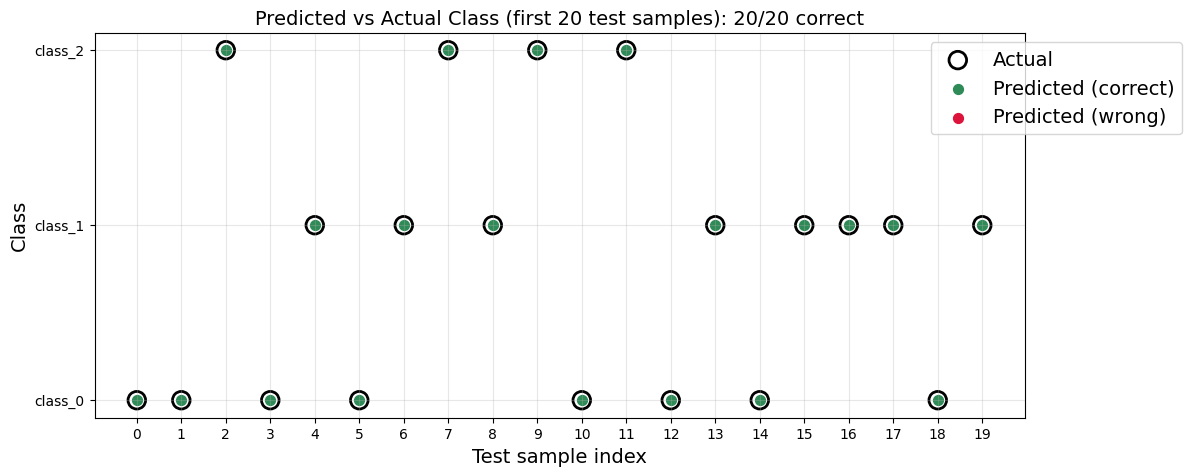

In [66]:
import matplotlib.pyplot as plt
import numpy as np

# Predictions from the tuned model for the first 20 test samples
y_pred = rnd_search_cv_wine.predict(_X_wine_test[:20])
y_true = np.array(_y_wine_test[:20])
idx = np.arange(20)
correct = y_pred == y_true

plt.figure(figsize=(12, 5))
plt.scatter(idx, y_true, s=160, facecolors='none', edgecolors='black',
            linewidths=2, label='Actual')
plt.scatter(idx[correct], y_pred[correct], s=50, color='seagreen',
            label='Predicted (correct)')
plt.scatter(idx[~correct], y_pred[~correct], s=50, color='crimson',
            label='Predicted (wrong)')

plt.xticks(idx)
plt.yticks([0, 1, 2], ['class_0', 'class_1', 'class_2'])
plt.xlabel('Test sample index')
plt.ylabel('Class')
plt.title(f'Predicted vs Actual Class (first 20 test samples): '
          f'{correct.sum()}/20 correct')
plt.legend(loc='upper right', bbox_to_anchor=(1.18, 1))
plt.grid(alpha=0.3)
plt.show()

## Reflection Questions

1. Two real-world applications of SVM

- Email spam filtering (technology):Each email is turned into numeric features, such as word frequencies, the number of links, or the sender's domain reputation. An SVM learns the boundary between spam and legitimate messages from labeled examples. SVMs work well here because text data has thousands of features, and SVMs handle high-dimensional data effectively. In practice, a linear SVM is often enough for this kind of text classification, and it is fast enough to scan large volumes of email.

- Credit card fraud detection (business):Each transaction is described by features such as amount, location, time of day, merchant type, and how it differs from the customer's usual spending. An SVM classifies each transaction as legitimate or fraudulent. A kernelized SVM is useful here because the boundary between normal and fraudulent behavior is rarely a straight line. Catching fraud early saves banks and customers money, and it is a direct business use of the same classification idea as the wine exercise.

2. Difference between LinearSVC and a kernelized SVM

`LinearSVC` finds a straight-line (linear) decision boundary, a flat hyperplane, between classes. It is fast and scales well to large datasets. It works best when the classes can be roughly separated by a straight boundary, and it has few hyperparameters to tune (mainly `C`). It handles multiple classes with the one-vs-rest strategy, which is why it worked in this assignment without extra setup.

A kernelized SVM, such as `SVC` with the RBF kernel, uses the kernel trick. It measures similarity between points as if the data were mapped into a much higher-dimensional space, where a flat boundary can separate the classes. When mapped back to the original features, that boundary is curved and flexible. This lets it capture complex, nonlinear patterns that `LinearSVC` cannot. The trade-offs are that training is slower on large datasets, and it needs more tuning (`C` and `gamma`) to avoid underfitting or overfitting. In this exercise, scaled `LinearSVC` reached about 97.7% accuracy, and tuning `gamma` and `C` let `SVC` reach about 97.8% in cross-validation. The wine classes are already well separated, so the nonlinear option gave only a small improvement.

3. Why visualize predicted vs actual results at the end

Accuracy is a single number that hides where the model went wrong. A predicted-vs-actual plot shows exactly which samples were misclassified and which classes were confused with each other, such as class 1 being mistaken for class 2. This helps in several ways:

- Error analysis: you can see whether mistakes are random or concentrated in one class, which points to what to improve (more data, better features, different tuning).
- Checking generalization:since the plot uses unseen test data, it confirms how the model behaves on new wines rather than on the data it trained on.
- Trust and communication:a visual is easier for classmates, instructors, or non-technical stakeholders to understand than a printed score, and it makes the result more convincing.
- Sanity check:it can reveal problems that accuracy alone would not, such as a model that always predicts the majority class.

4. AI usage statement

I used Gemini, an AI assistant, as a support tool in this assignment. It helped me debug errors in my Chapter 6 code (indentation, typos, and seaborn and matplotlib issues) and draft the Markdown explanations, the predicted-vs-actual visualization code, and the reflection answers. I typed, ran, and tested all of the code in Google Colab myself, reviewed the outputs, and checked the explanations against the textbook and my own results. I take responsibility for the final submitted work.